This follows the path laid out in 'FullFit_ordered1.ipynb' and starts off from the progress and framework made in reflectivity_fitting_v3.ipynb

---
### Imports

Importing and calling ...../Fitting/GenPaths.py
added to path: ['/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/Fitting', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling']
PROPATH variable: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


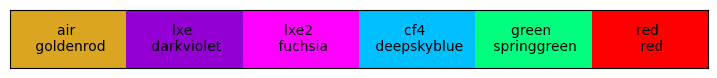

In [1]:
from GenPaths import * # this provides PROPATH which helps load stuff (and the paths to find the PDEhelpers stuff)

import pandas as pd
import matplotlib.pyplot as plt

from scipy import optimize as opt
import iminuit
from iminuit import Minuit

from PDEhelpers.OpticsDataLoader import *
import PDEhelpers.MathEquations as ME
from PDEhelpers.PhotonInfo import * # this calls DataLoader when defining init
# from PDEhelpers.PNJunction import *
import PDEhelpers.PNJunction as PNJ

import PDE_fittingTools as SS

import PDEhelpers.PDEStyle as MS
MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option


In [2]:
# %run "PDE_fittingFunction.py"

In [3]:
######## High level Fitting Functions ########
def PDE_allArgs(wlen, theta1, FF, tOxide, dp_star, Xpn, dw_star, pe, ph, smoothSigma=None, quantum = False):
    
    photon = PhotonInfo(wlen, theta1)    
    Ttotal = photon.Wave_TotalTransmission(tOxide)
    pn = PNJ.PNJunction(tOxide = tOxide, dp_star = dp_star, Xpn = Xpn, dw_star=dw_star, pe = pe, ph = ph)
    Wp, Wn = pn.calcW_both(photon)
    
    if quantum:
        nyield = (1240/wlen)/3.2
        pe = 1-(1-pe)**nyield
    PDE = FF * Ttotal * (Wp*pe + Wn*ph)
    
    if smoothSigma is not None: # expensive but simple/works/robust
        stepPerSigma = 3
        stepSize = smoothSigma / stepPerSigma
        newXVals = np.arange(min(wlen), max(wlen) + stepSize, stepSize)
        fullerPDEVals = PDE_allArgs(newXVals, theta1, FF, tOxide, dp_star, Xpn, dw_star, pe, ph, smoothSigma = None)
        fullerPDEVals = gaussian_filter1d(fullerPDEVals, sigma=smoothSigma)
        pdeInt = interp1d(newXVals, fullerPDEVals, kind='linear', fill_value=0)
        return pdeInt(wlen)
        
    return PDE

---
### Loading Data

In [4]:
file_path = os.path.join(PROPATH, "../veraData/HPK_IR_PDE-Feb12_2024-Harry.csv")
df = pd.read_csv(file_path, header=0)

# print(df)
# print(df.info())
print(df.tail())
print("--------------------------")

print(df['Overvoltage'].value_counts())
print(df['Angle'].value_counts())

data_angles = df['Angle'].unique()
data_voltages = df['Overvoltage'].unique()

# print("Angles:", data_angles)
# print("voltages:", data_voltages)



      Wavelength  Angle  Overvoltage  Responsivity       PDE  PDE_error
2188     799.979     60            6  3.429750e-14  0.041089   0.004239
2189     809.978     60            6  3.299900e-14  0.039534   0.003863
2190     820.008     60            6  3.095340e-14  0.037083   0.003730
2191     830.012     60            6  2.754830e-14  0.033003   0.003196
2192     830.012     60            6  2.754830e-14  0.033003   0.003196
--------------------------
Overvoltage
0    260
1    255
2    255
3    255
4    255
5    255
6    254
7    204
8    200
Name: count, dtype: int64
Angle
0     459
15    459
30    459
45    459
60    357
Name: count, dtype: int64


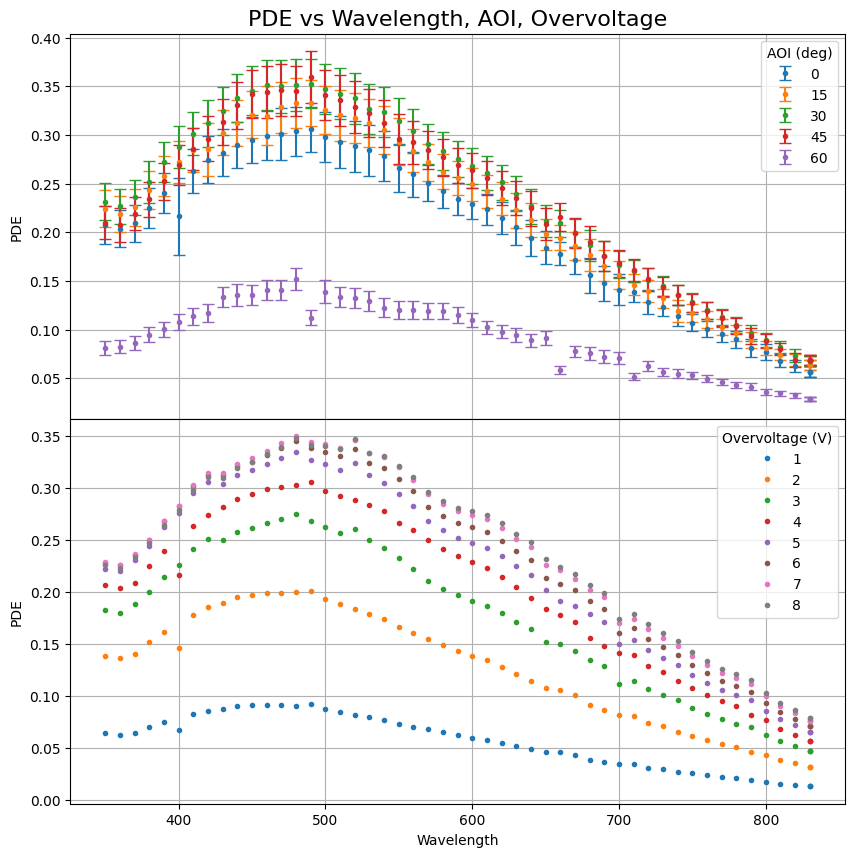

Angles: [0 1 2 3 4 5 6 7 8]
voltages: [0 1 2 3 4 5 6 7 8]


In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize = (10, 10))

# xv4 = df[df['Overvoltage'] == 4]
for angle in data_angles:
    dt1 = df[(df['Angle'] == angle) & (df['Overvoltage'] == 4)]

    dt1.plot(x='Wavelength', y = "PDE", yerr="PDE_error", capsize=4, label = f"{angle:0.0f}", linestyle = "", marker = ".", ax = ax1)
    
ax1.legend(title = "AOI (deg)")
ax1.set_ylabel("PDE")

for voltage in data_voltages[1:]:
    dt2 = df[(df['Angle'] == 0) & (df['Overvoltage'] == voltage)]
    dt2.plot(x='Wavelength', y = "PDE",label = f"{voltage:0.0f}", linestyle = "", marker = ".", ax = ax2)

ax2.legend(title = "Overvoltage (V)")
ax2.set_ylabel("PDE")

ax1.grid(), ax2.grid()
ax1.set_title("PDE vs Wavelength, AOI, Overvoltage", fontsize = 16)
plt.subplots_adjust(hspace=0)
plt.show()
print("Angles:", data_voltages)
print("voltages:", data_voltages)

In [6]:
##-- Buiding All datasets --##
scaleErrors = 1.0
# dataset 0A
v_0A = data_voltages[-1]
v_0A2 = data_voltages[-2]
angle_0A = data_angles[0]

dfA = df[(df['Overvoltage'] == v_0A) & (df['Angle'] == angle_0A)]
dfA2 = df[(df['Overvoltage'] == v_0A2) & (df['Angle'] == angle_0A)]
dataA = [
    {"wlen":dfA['Wavelength'], "yVals": dfA['PDE'], "yErrs": dfA['PDE_error']*scaleErrors, "theta1": data_angles[0]},
    {"wlen":dfA2['Wavelength'], "yVals": dfA2['PDE'], "yErrs": dfA2['PDE_error']*scaleErrors, "theta1": data_angles[0]}
    ]

print("voltage wanted:", v_0A, "V")
print("angle wanted:", angle_0A, "deg")

SS.CheckDataSetKey_consistent(dataA)
# keys1 = 
# all_same_keys = all(set(d.keys()) == keys1 for d in dataObj)

voltage wanted: 8 V
angle wanted: 0 deg


True

---
## Fit All Junction Parameters, all voltages: why not!
#### Case 0A: High V, float the rest

In [7]:
ttGood = 16.0 # if only 50um data, use 16.0nm
ttGood = 12.0
FF1 = 0.6

print("List of args needed:", SS.GetNames(PDE_allArgs))

parsBoring = {"FF": FF1, "quantum": False, "smoothSigma": None}
fixedPars_A = {"tOxide": ttGood, **parsBoring}
floatPars_A = {"dp_star": 10, "Xpn": 2e3, "dw_star": 4e3, "ph": 0.5,  "pe": 1.0}
# floatPars_A2N = {"dp_star": 1.5, "Xpn": 2e3, "dw_star": 2e3, "ph": 1.0,  "pe": 0.8}
# floatPars_A2P = {"dp_star": 0, "Xpn": 1e3, "dw_star": 4e3, "ph": 0.5,  "pe": 0.85}

floatBounds_A = {"dp_star": (0.5, 50)}
SS.AddNonesToDict(dAddTo=floatBounds_A, dRef=floatPars_A)

print("------ Case 0A setup ------")
SS.CheckAllConditions_forResiduals(func=PDE_allArgs, dataObj=dataA, dFixed=fixedPars_A, dFloat=floatPars_A, yNames=("yVals", "yErrs"), verbose=False)

xoA, xoANames = SS.BuildX0(floatDict=floatPars_A, functionToFit=PDE_allArgs)
xABounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_A, functionToFit=PDE_allArgs)
PDE_allArgs(wlen=dataA[0]["wlen"], theta1=dataA[0]["theta1"], **floatPars_A, **fixedPars_A);
SS.GenericResiduals(x0=xoA, fixedArgs_dict=fixedPars_A, dataObj=dataA, functionToFit=PDE_allArgs, verbose=False)


List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum']
------ Case 0A setup ------
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_crystalline_lithoAndSchinke_merged.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------


153.36996500373874

------ Case 0A Fit ------
  message: Optimization terminated successfully.
  success: True
      fun: 6.358717023481674
        x: [ 1.140e+00  2.288e+03  1.569e+04  9.351e-01  1.436e-01]
 hess_inv: ┌────┬───────────────────────────────────────────────────┐
           │    │        x0        x1        x2        x3        x4 │
           ├────┼───────────────────────────────────────────────────┤
           │ x0 │     0.207    -34.03   -286.99   4.13e-3    0.0038 │
           │ x1 │    -34.03  4.56e+04    0.77e6  -2.40304   -8.4162 │
           │ x2 │   -286.99    0.77e6  2.62e+07 -20.65302 -215.4514 │
           │ x3 │   4.13e-3  -2.40304 -20.65302  0.000281   0.27e-3 │
           │ x4 │    0.0038   -8.4162 -215.4514   0.27e-3   0.00203 │
           └────┴───────────────────────────────────────────────────┘
     nfev: 398
     njev: 0
   minuit: ┌─────────────────────────────────────────────────────────────────────────┐
           │                                Migrad                 

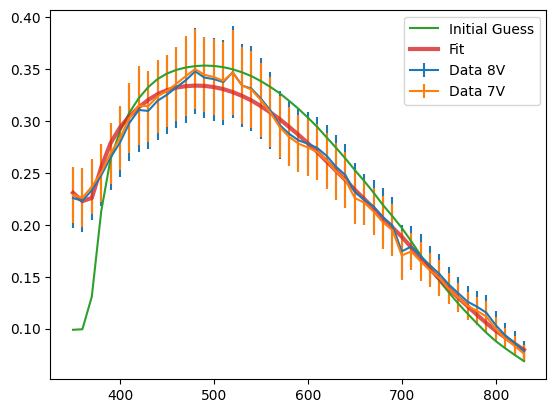

In [8]:
print("------ Case 0A Fit ------")
result = iminuit.minimize(SS.GenericResiduals, x0=xoA, bounds = xABounds, args=(fixedPars_A, dataA, PDE_allArgs), method='migrad')
resErrors = SS.GetErrorFromInvHess(result.hess_inv)
print(result)
# print(result.x)
# print(xoANames)

fitScore_0A = result.fun
resultDict_0A = {xoANames[i]: round(result.x[i], 3) for i in range(len(xoANames))}
resultDErrors_0A = {xoANames[i]: round(resErrors[i], 3) for i in range(len(xoANames))}
print("result dict:", resultDict_0A)
print("result errors:", resultDErrors_0A)

plt.errorbar(x=dataA[0]["wlen"], y=dataA[0]["yVals"], yerr=dataA[0]["yErrs"], label = "Data 8V")
plt.errorbar(x=dataA[1]["wlen"], y=dataA[1]["yVals"], yerr=dataA[1]["yErrs"], label = "Data 7V")

plt.plot(dataA[0]["wlen"], PDE_allArgs(wlen=dataA[0]["wlen"], theta1=dataA[0]["theta1"], **floatPars_A, **fixedPars_A), label = "Initial Guess")
plt.plot(dataA[0]["wlen"], PDE_allArgs(wlen=dataA[0]["wlen"], theta1=dataA[0]["theta1"], **resultDict_0A, **fixedPars_A), linewidth = 3, alpha = 0.8, label = "Fit")

plt.legend()
plt.show()

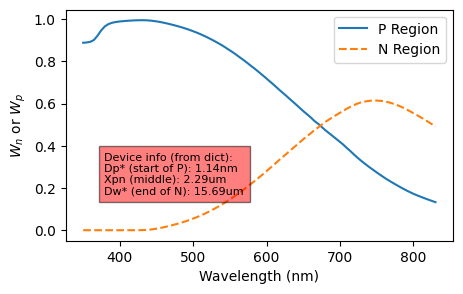

In [9]:
# check the Wn, Wp values from the fit results
PNJ.Plot_Ws(someDictOfStuff=resultDict_0A, xRange=(min(dataA[0]["wlen"]), max(dataA[0]["wlen"])));

---
### Fitting All Junction Parameters: reduce V! - Float Everything
#### Case 0B: Lower V, fixed from above

In [10]:
print("data voltages:", data_voltages, "V")
print("data angles:", data_angles, "deg")

print("getting data for angle", angle_0A)

print(resultDict_0A)

data_voltages[-2:1:-1]

data voltages: [0 1 2 3 4 5 6 7 8] V
data angles: [ 0 15 30 45 60] deg
getting data for angle 0
{'dp_star': 1.14, 'Xpn': 2288.452, 'dw_star': 15693.949, 'pe': 0.935, 'ph': 0.144}


array([7, 6, 5, 4, 3, 2])

In [11]:
results_list = [resultDict_0A]
resErrors_list = [resultDErrors_0A]
scoreList = [fitScore_0A]
for voltageWanted in data_voltages[-3:1:-1]:
    print("---------------------------")
    print("voltage wanted:", voltageWanted, "V")

    dfA = df[(df['Overvoltage'] == voltageWanted) & (df['Angle'] == angle_0A)]
    
    # data object
    dataA_lowerV = [{"wlen":dfA['Wavelength'], "yVals": dfA['PDE'], "yErrs": dfA['PDE_error']*scaleErrors, "theta1": data_angles[0]}]
    
    # parameter setup
    fixedPars_A_lowerV = {"tOxide": ttGood, **parsBoring}
    floatPars_A_lowerV = {**resultDict_0A}
    floatPars_A_lowerV["pe"] = round(   np.sqrt(floatPars_A_lowerV["pe"] * voltageWanted / v_0A), 4) # change pe guess
    print(f"pe guess for {voltageWanted} V:", floatPars_A_lowerV["pe"])
    
    floatBounds_A = {"dp_star": (0.5, 50)}
    SS.AddNonesToDict(dAddTo=floatBounds_A, dRef=floatPars_A_lowerV)
    SS.CheckAllConditions_forResiduals(func=PDE_allArgs, dataObj=dataA_lowerV, dFixed=fixedPars_A_lowerV, dFloat=floatPars_A_lowerV, yNames=("yVals", "yErrs"), verbose=False)

    # sorting
    xoA, xoANames = SS.BuildX0(floatDict=floatPars_A_lowerV, functionToFit=PDE_allArgs)
    xABounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_A, functionToFit=PDE_allArgs)
    # PDE_allArgs(wlen=dataA_lowerV[0]["wlen"], theta1=dataA_lowerV[0]["theta1"], **floatPars_A_lowerV, **fixedPars_A_lowerV);
    # SS.GenericResiduals(x0=xoA, fixedArgs_dict=fixedPars_A_lowerV, dataObj=dataA_lowerV, functionToFit=PDE_allArgs, verbose=False)
    
    result = iminuit.minimize(SS.GenericResiduals, x0=xoA, bounds = xABounds, args=(fixedPars_A_lowerV, dataA_lowerV, PDE_allArgs), method='migrad')
    resErrors = SS.GetErrorFromInvHess(result.hess_inv)
    # print(result)
    # print(result.x)
    # print(xoANames)

    resultDict_0A = {xoANames[i]: round(result.x[i], 3) for i in range(len(xoANames))}
    results_list.append(resultDict_0A)
    
    resultDErrors_0A = {xoANames[i]: round(resErrors[i], 3) for i in range(len(xoANames))}
    resErrors_list.append(resultDErrors_0A)
    
    scoreList.append(result.fun)
    
    print("result dict:", resultDict_0A)
    print("result errors:", resultDErrors_0A)

---------------------------
voltage wanted: 6 V
pe guess for 6 V: 0.8374
result dict: {'dp_star': 1.094, 'Xpn': 2034.937, 'dw_star': 14898.55, 'pe': 0.935, 'ph': 0.139}
result errors: {'dp_star': 0.554, 'Xpn': 216.828, 'dw_star': 5282.363, 'pe': 0.021, 'ph': 0.048}
---------------------------
voltage wanted: 5 V
pe guess for 5 V: 0.7644
result dict: {'dp_star': 1.101, 'Xpn': 1911.424, 'dw_star': 15529.54, 'pe': 0.914, 'ph': 0.124}
result errors: {'dp_star': 0.499, 'Xpn': 168.631, 'dw_star': 4907.613, 'pe': 0.019, 'ph': 0.036}
---------------------------
voltage wanted: 4 V
pe guess for 4 V: 0.676
result dict: {'dp_star': 0.985, 'Xpn': 1984.925, 'dw_star': 15230.851, 'pe': 0.834, 'ph': 0.095}
result errors: {'dp_star': 0.49, 'Xpn': 171.083, 'dw_star': 5686.532, 'pe': 0.017, 'ph': 0.033}
---------------------------
voltage wanted: 3 V
pe guess for 3 V: 0.5592
result dict: {'dp_star': 1.183, 'Xpn': 1755.243, 'dw_star': 16031.455, 'pe': 0.753, 'ph': 0.079}
result errors: {'dp_star': 0.547,

[7 6 5 4 3 2]
keys dict_keys(['dp_star', 'Xpn', 'dw_star', 'pe', 'ph'])


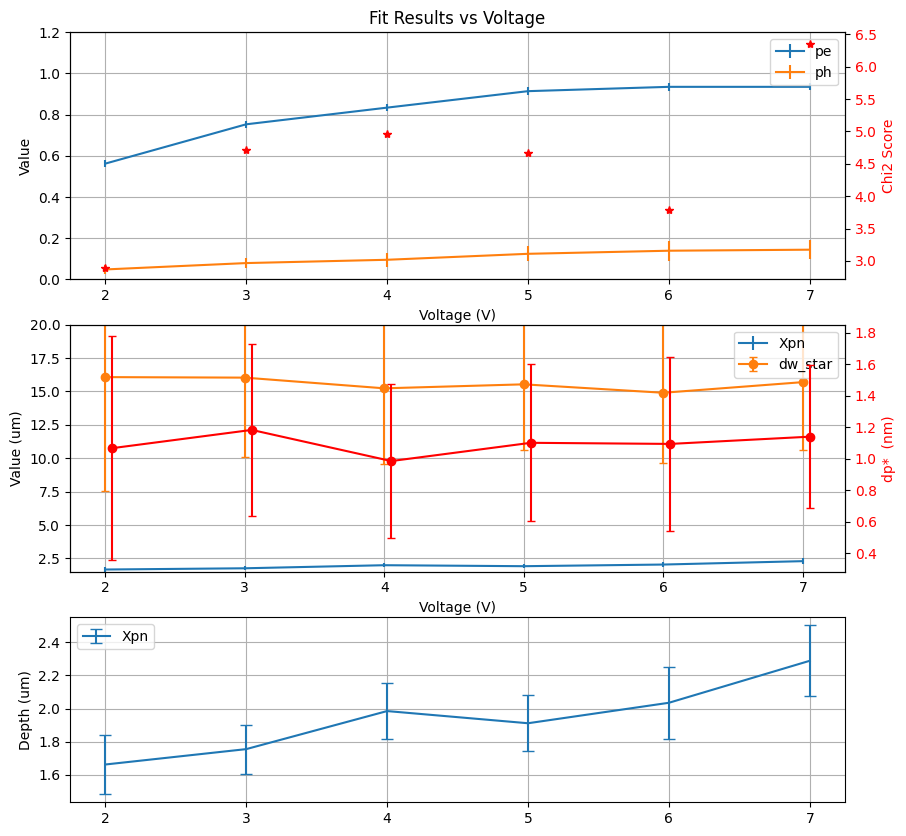

In [12]:
## sorting outputs from fit
xVals = np.array(data_voltages[-2:1:-1])
print(xVals)
print("keys", results_list[0].keys())

getArray = lambda key, dictList: np.array([d[key] for d in dictList]) # build array from list of dicts

varsDict = {}
errorsDict = {}
for key in results_list[0].keys():
    vName = "yVals_"+key
    yVals = getArray(key, results_list)
    varsDict[vName] = yVals
    
    vEName = "yErrs_"+key
    yErrs = getArray(key, resErrors_list)
    errorsDict[vEName] = yErrs

## plotting
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 10), height_ratios=[4, 4, 3])
ax1.errorbar(x=xVals, y=varsDict["yVals_pe"], yerr=errorsDict["yErrs_pe"], label = "pe")
ax1.errorbar(x=xVals, y=varsDict["yVals_ph"], yerr=errorsDict["yErrs_ph"], label = "ph")

ax1_1 = ax1.twinx()
ax1_1.set_ylabel('Chi2 Score', color="red")  # we already handled the x-label with ax1
ax1_1.tick_params(axis='y', labelcolor="red")
ax1_1.plot(xVals, scoreList, linestyle="None", marker = "*", color = "red", label = "Chi2 Score")

ax1.set_ylim(0, 1.2)
ax1.set_xlabel("Voltage (V)")
ax1.set_ylabel("Value")
ax1.set_title("Fit Results vs Voltage")
ax1.legend()
ax1.grid()

ax2.errorbar(x=xVals, y=varsDict["yVals_Xpn"]/1000, yerr=errorsDict["yErrs_Xpn"]/1000, label = "Xpn")
ax2.errorbar(x=xVals, y=varsDict["yVals_dw_star"]/1000, yerr=errorsDict["yErrs_dw_star"]/1000, capsize=3, marker = "o", label = "dw_star")

ax2_1 = ax2.twinx()
ax2_1.set_ylabel('dp*  (nm)', color="red")  # we already handled the x-label with ax1
ax2_1.tick_params(axis='y', labelcolor="red")
ax2_1.errorbar(x=xVals+0.05, y=varsDict["yVals_dp_star"], yerr=errorsDict["yErrs_dp_star"], capsize=3, marker = "o", color = "red", label = "dp_star (shift x)")

ax2.grid()
ax2.legend()
ax2.set_ylim(1.5, 20)
ax2.set_xlabel("Voltage (V)")
ax2.set_ylabel("Value (um)")

ax3.errorbar(x=xVals, y=varsDict["yVals_Xpn"]/1000, yerr=errorsDict["yErrs_Xpn"]/1000, capsize=4, label = "Xpn")
ax3.set_ylabel("Depth (um)")
ax3.legend()
ax3.grid()

plt.show()

In [13]:
fixedPars_Averages = {"tOxide": ttGood, "FFH":10, **parsBoring}
floatPars_Set = {"tOxide":16.5, "tOxide":16.5, "Xpn": 10}

sharedKey = set(fixedPars_Averages.keys()).intersection(floatPars_Set.keys())
sharedKey

{'tOxide'}

---
### Fix dp*, dw*, Xpn globally

In [14]:
meanXpn = np.mean(varsDict["yVals_Xpn"])
meanDw = np.mean(varsDict["yVals_dw_star"])
meanDp = np.mean(varsDict["yVals_dp_star"])

print("mean Xpn:", meanXpn)
print("mean Dw:", meanDw)
print("mean Dp:", meanDp)

fixedPars_Averages = {"tOxide":16.5, **parsBoring}
# fixedPars_Averages = {**parsBoring}
fixed_to_add = {"Xpn": meanXpn,"dw_star": meanDw, "dp_star": meanDp}
fixedPars_Averages.update(fixed_to_add)


listXpn = []
listPE = []
listPH = []
listTo = []
listVoltage_fixed = []
for voltageWanted in data_voltages[-1:1:-1]:
    print("---------------------------")
    print("voltage wanted:", voltageWanted, "V")

    dfA = df[(df['Overvoltage'] == voltageWanted) & (df['Angle'] == angle_0A)]
    
    # data object
    data_FixedMore = [{"wlen":dfA['Wavelength'], "yVals": dfA['PDE'], "yErrs": dfA['PDE_error']*scaleErrors, "theta1": data_angles[0]}]
    
    # parameter setup
    # floatPars_Set = {"Xpn": meanXpn}
    floatPars_Set = {}
    floatPars_Set["pe"] = np.sqrt(0.9 * voltageWanted / v_0A) # change pe guess
    floatPars_Set["ph"] = 0.2
    
    # SS.AddNonesToDict(dAddTo=floatBounds_A, dRef=floatPars_Set)
    SS.CheckAllConditions_forResiduals(func=PDE_allArgs, dataObj=data_FixedMore, dFixed=fixedPars_Averages, dFloat=floatPars_Set, yNames=("yVals", "yErrs"), verbose=False)

    # sorting
    xoA, xoANames = SS.BuildX0(floatDict=floatPars_Set, functionToFit=PDE_allArgs)
    
    # PDE_allArgs(wlen=data_FixedMore[0]["wlen"], theta1=data_FixedMore[0]["theta1"], **floatPars_Set, **fixedPars_A_lowerV);
    # SS.GenericResiduals(x0=xoA, fixedArgs_dict=fixedPars_A_lowerV, dataObj=data_FixedMore, functionToFit=PDE_allArgs, verbose=False)
    
    result = iminuit.minimize(SS.GenericResiduals, x0=xoA, bounds = None, args=(fixedPars_Averages, data_FixedMore, PDE_allArgs), method='migrad')
    resErrors = SS.GetErrorFromInvHess(result.hess_inv)
    # print(result)
    # print(result.x)
    # print(xoANames)

    resultDict_0A = {xoANames[i]: round(result.x[i], 3) for i in range(len(xoANames))}
    results_list.append(resultDict_0A)
    
    resultDErrors_0A = {xoANames[i]: round(resErrors[i], 3) for i in range(len(xoANames))}
    resErrors_list.append(resultDErrors_0A)
    
    scoreList.append(result.fun)
    
    print("result dict:", resultDict_0A)
    print("result errors:", resultDErrors_0A)
    
    # listXpn.append(resultDict_0A["Xpn"])
    listPE.append(resultDict_0A["pe"])
    listPH.append(resultDict_0A["ph"])
    listVoltage_fixed.append(voltageWanted)
    # listTo.append(resultDict_0A["tOxide"])
floatPars_Averages = {"pe": 1.0, "ph": 0.2}

mean Xpn: 1939.5638333333334
mean Dw: 15575.728166666668
mean Dp: 1.095
---------------------------
voltage wanted: 8 V
result dict: {'pe': 0.938, 'ph': 0.195}
result errors: {'pe': 0.015, 'ph': 0.012}
---------------------------
voltage wanted: 7 V
result dict: {'pe': 0.945, 'ph': 0.173}
result errors: {'pe': 0.014, 'ph': 0.01}
---------------------------
voltage wanted: 6 V
result dict: {'pe': 0.928, 'ph': 0.149}
result errors: {'pe': 0.012, 'ph': 0.009}
---------------------------
voltage wanted: 5 V
result dict: {'pe': 0.896, 'ph': 0.125}
result errors: {'pe': 0.01, 'ph': 0.007}
---------------------------
voltage wanted: 4 V
result dict: {'pe': 0.825, 'ph': 0.101}
result errors: {'pe': 0.01, 'ph': 0.007}
---------------------------
voltage wanted: 3 V
result dict: {'pe': 0.723, 'ph': 0.069}
result errors: {'pe': 0.009, 'ph': 0.006}
---------------------------
voltage wanted: 2 V
result dict: {'pe': 0.532, 'ph': 0.036}
result errors: {'pe': 0.009, 'ph': 0.006}


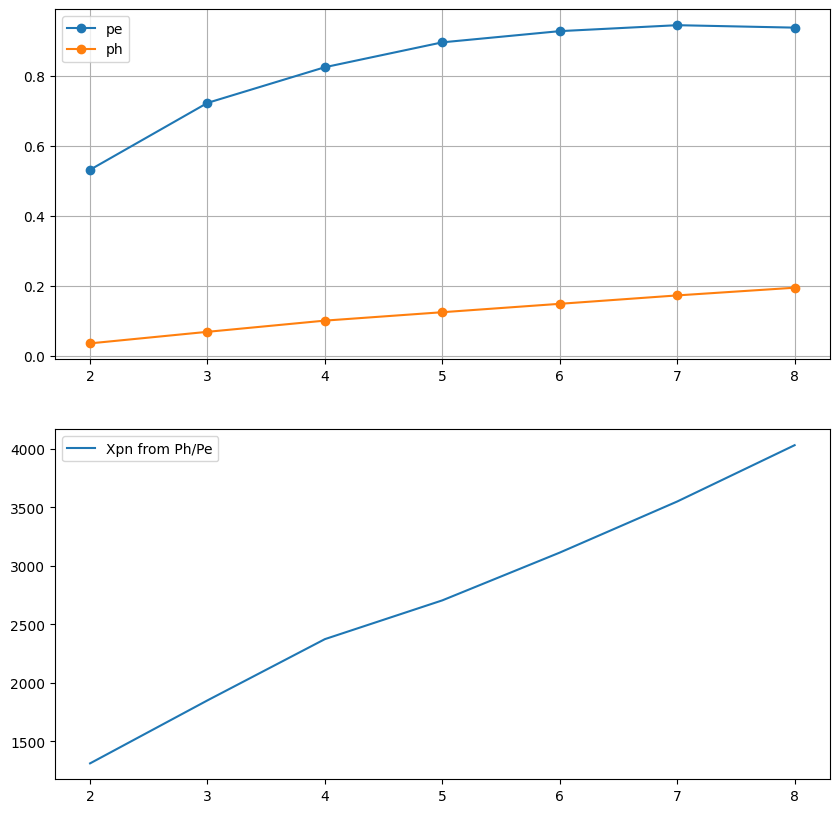

In [15]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10))

ax1.plot(listVoltage_fixed, listPE, marker='o', label = "pe")
ax1.plot(listVoltage_fixed, listPH, marker='o', label = "ph")
ax1.legend()
ax1.grid()

# ax2.plot(listVoltage_fixed, listXpn, label = "Xpn")
ax2.plot(listVoltage_fixed, np.array(listPH)/np.array(listPE) * 10*meanXpn, label = "Xpn from Ph/Pe")
# ax2.grid()

plt.legend()

---
### Fix dp*, dw*, Xpn globally, float tOxide

In [23]:
meanXpn = np.mean(varsDict["yVals_Xpn"])
meanDw = np.mean(varsDict["yVals_dw_star"])
meanDp = np.mean(varsDict["yVals_dp_star"])

print("mean Xpn:", meanXpn)
print("mean Dw:", meanDw)
print("mean Dp:", meanDp)

fixedPars_Averages = {**parsBoring}
fixed_to_add = {"dw_star": meanDw, "dp_star": meanDp}
fixedPars_Averages.update(fixed_to_add)


listXpn = []
listPE = []
listPH = []
listTo = []
listVoltage_fixed = []
for voltageWanted in data_voltages[-1:1:-1]:
    print("---------------------------")
    print("voltage wanted:", voltageWanted, "V")

    dfA = df[(df['Overvoltage'] == voltageWanted) & (df['Angle'] == angle_0A)]
    
    # data object
    data_FixedMore = [{"wlen":dfA['Wavelength'], "yVals": dfA['PDE'], "yErrs": dfA['PDE_error']*scaleErrors, "theta1": data_angles[0]}]
    
    # parameter setup
    # floatPars_Set = {"Xpn": meanXpn}
    floatPars_Set = {"tOxide":16.5, "Xpn": meanXpn}
    floatPars_Set["pe"] = np.sqrt(0.9 * voltageWanted / v_0A) # change pe guess
    floatPars_Set["ph"] = 0.2
    
    # SS.AddNonesToDict(dAddTo=floatBounds_A, dRef=floatPars_Set)
    SS.CheckAllConditions_forResiduals(func=PDE_allArgs, dataObj=data_FixedMore, dFixed=fixedPars_Averages, dFloat=floatPars_Set, yNames=("yVals", "yErrs"), verbose=False)

    # sorting
    xoA, xoANames = SS.BuildX0(floatDict=floatPars_Set, functionToFit=PDE_allArgs)
    
    # PDE_allArgs(wlen=data_FixedMore[0]["wlen"], theta1=data_FixedMore[0]["theta1"], **floatPars_Set, **fixedPars_A_lowerV);
    # SS.GenericResiduals(x0=xoA, fixedArgs_dict=fixedPars_A_lowerV, dataObj=data_FixedMore, functionToFit=PDE_allArgs, verbose=False)
    
    result = iminuit.minimize(SS.GenericResiduals, x0=xoA, bounds = None, args=(fixedPars_Averages, data_FixedMore, PDE_allArgs), method='migrad')
    resErrors = SS.GetErrorFromInvHess(result.hess_inv)
    # print(result)
    # print(result.x)
    # print(xoANames)

    resultDict_0A = {xoANames[i]: round(result.x[i], 3) for i in range(len(xoANames))}
    results_list.append(resultDict_0A)
    
    resultDErrors_0A = {xoANames[i]: round(resErrors[i], 3) for i in range(len(xoANames))}
    resErrors_list.append(resultDErrors_0A)
    
    scoreList.append(result.fun)
    
    print("result dict:", resultDict_0A)
    print("result errors:", resultDErrors_0A)
    
    # listXpn.append(resultDict_0A["Xpn"])
    listPE.append(resultDict_0A["pe"])
    listPH.append(resultDict_0A["ph"])
    listVoltage_fixed.append(voltageWanted)
    listTo.append(resultDict_0A["tOxide"])
floatPars_Averages = {"pe": 1.0, "ph": 0.2}

mean Xpn: 1939.5638333333334
mean Dw: 15575.728166666668
mean Dp: 1.095
---------------------------
voltage wanted: 8 V
result dict: {'tOxide': 6.507, 'Xpn': 2269.837, 'pe': 0.947, 'ph': 0.154}
result errors: {'tOxide': 15.221, 'Xpn': 265.356, 'pe': 0.044, 'ph': 0.026}
---------------------------
voltage wanted: 7 V
result dict: {'tOxide': 7.01, 'Xpn': 2169.909, 'pe': 0.958, 'ph': 0.144}
result errors: {'tOxide': 14.225, 'Xpn': 229.342, 'pe': 0.044, 'ph': 0.021}
---------------------------
voltage wanted: 6 V
result dict: {'tOxide': 8.639, 'Xpn': 2009.657, 'pe': 0.948, 'ph': 0.136}
result errors: {'tOxide': 11.772, 'Xpn': 188.266, 'pe': 0.043, 'ph': 0.017}
---------------------------
voltage wanted: 5 V
result dict: {'tOxide': 8.249, 'Xpn': 1870.638, 'pe': 0.928, 'ph': 0.125}
result errors: {'tOxide': 10.998, 'Xpn': 150.898, 'pe': 0.038, 'ph': 0.013}
---------------------------
voltage wanted: 4 V
result dict: {'tOxide': 10.011, 'Xpn': 1955.036, 'pe': 0.843, 'ph': 0.095}
result errors:

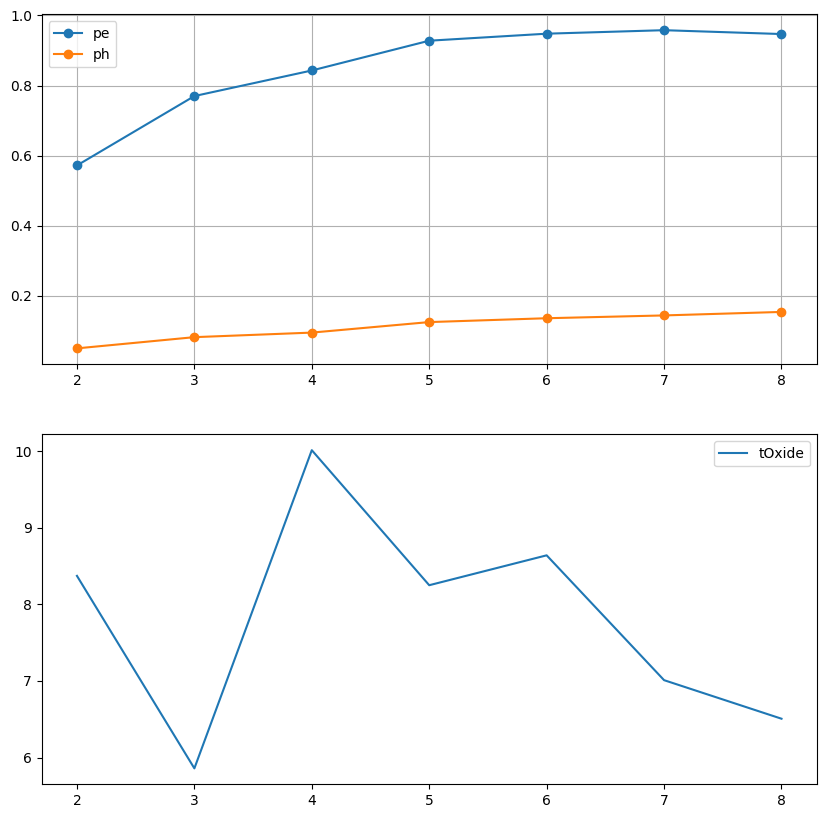

In [24]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10))

ax1.plot(listVoltage_fixed, listPE, marker='o', label = "pe")
ax1.plot(listVoltage_fixed, listPH, marker='o', label = "ph")
ax1.legend()
ax1.grid()

# ax2.plot(listVoltage_fixed, listXpn, label = "Xpn")
ax2.plot(listVoltage_fixed, listTo, label = "tOxide")
# ax2.grid()

plt.legend()

---
## Procedural UV --> Vis (proper methodology)
### UV Fit first


In [18]:
##-- Buiding UV datasets --##
scaleErrors = 1.0
# dataset 0A
v_0A = data_voltages[-1]
v_0A2 = data_voltages[-2]
angle_0A = data_angles[0]

dfA = df[(df['Overvoltage'] == v_0A) & (df['Angle'] == angle_0A)]
dfA2 = df[(df['Overvoltage'] == v_0A2) & (df['Angle'] == angle_0A)]
dataA = [
    {"wlen":dfA['Wavelength'], "yVals": dfA['PDE'], "yErrs": dfA['PDE_error']*scaleErrors, "theta1": data_angles[0]},
    {"wlen":dfA2['Wavelength'], "yVals": dfA2['PDE'], "yErrs": dfA2['PDE_error']*scaleErrors, "theta1": data_angles[0]}
    ]

print("voltage wanted:", v_0A, "V")
print("angle wanted:", angle_0A, "deg")

SS.CheckDataSetKey_consistent(dataA)
# keys1 = 
# all_same_keys = all(set(d.keys()) == keys1 for d in dataObj)

voltage wanted: 8 V
angle wanted: 0 deg


True